# 28 — GeoMAE-Inspired Anomaly Map Visualization
## Visual bridge from next-day hotspot risk → contextual anomaly identification

This notebook creates a visualization similar in spirit to the previous
**predicted grid risk vs raw FIRMS points** figure.

### Previous visualization
**Where is a hotspot likely to appear at t+1?**

### This visualization
**Among hotspot-positive cells that actually occurred, which ones are unusual relative to the learned temporal context?**

The figure contains two panels:

1. **Observed hotspot activity**
   - grid color = observed FIRMS detection count in the cell;
   - orange points = raw FIRMS detections if available.

2. **GeoMAE-inspired contextual anomaly**
   - grid color = five-seed ensemble anomaly rank;
   - `×` marker = frozen robust anomaly candidate;
   - orange points = raw FIRMS detections if available.

Important:
- anomaly rank is not an ignition-cause probability;
- `×` does not mean human-caused or illegal burning;
- it means the hotspot cell-day was consistently difficult to reconstruct from preceding temporal fire context.

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)

In [3]:
cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    export_dir = (
        root
        / "model_results"
        / "final_masked_temporal_anomaly"
        / "t2"
        / "exports"
    )

    required = [
        export_dir / "august_all_cells_multiseed_scores.csv",
        export_dir / "august_final_robust_anomaly_candidates.csv",
    ]

    if all(p.exists() for p in required):
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate NB25 exports. "
        "Run NB25 first or adjust PROJECT_ROOT manually."
    )

EXPORT25 = (
    PROJECT_ROOT
    / "model_results"
    / "final_masked_temporal_anomaly"
    / "t2"
    / "exports"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "anomaly_map_visualization"
    / "t2"
)

FIG_DIR = RESULT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("FIG_DIR:", FIG_DIR)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
FIG_DIR: c:\Users\Asus\Documents\skripsi-karhut\model_results\anomaly_map_visualization\t2\figures


In [4]:
scores = pd.read_csv(
    EXPORT25 / "august_all_cells_multiseed_scores.csv",
    parse_dates=["date"],
)

candidates = pd.read_csv(
    EXPORT25 / "august_final_robust_anomaly_candidates.csv",
    parse_dates=["date"],
)

analysis_path = (
    EXPORT25
    / "august_hotspot_candidate_analysis.csv"
)

analysis = None
if analysis_path.exists():
    analysis = pd.read_csv(
        analysis_path,
        parse_dates=["event_date"],
    )

print("Score rows:", len(scores))
print("Dates:", scores["date"].min().date(), "→", scores["date"].max().date())
print("Frozen robust candidates:", len(candidates))

Score rows: 4123
Dates: 2026-08-01 → 2026-08-31
Frozen robust candidates: 620


## Choose the date to visualize

Default is **2026-08-02**, because it contains a clear Emerging-3 case used in the thesis case-study analysis.

You may change `TARGET_DATE` to any August date contained in NB25.

For a direct visual comparison with the previous **2026-09-02** prediction map, September first needs to be scored with the frozen anomaly model. That is a separate scoring step and should be labeled as an illustrative/post-development analysis.

In [5]:
TARGET_DATE = pd.Timestamp("2026-08-02")

available_dates = set(pd.to_datetime(scores["date"]).dt.normalize())

if TARGET_DATE.normalize() not in available_dates:
    raise ValueError(
        f"{TARGET_DATE.date()} is not in the NB25 August score table."
    )

day = scores[
    scores["date"].dt.normalize().eq(TARGET_DATE.normalize())
].copy()

day_hot = day[
    day["fire_active"].eq(1)
].copy()

day_candidates = day_hot[
    day_hot["robust_anomaly_candidate"].eq(True)
].copy()

print("TARGET_DATE:", TARGET_DATE.date())
print("Grid cells:", len(day))
print("Hotspot-positive cells:", len(day_hot))
print("Robust anomaly candidates:", len(day_candidates))

TARGET_DATE: 2026-08-02
Grid cells: 133
Hotspot-positive cells: 35
Robust anomaly candidates: 21


In [6]:
if analysis is not None:
    group_info = (
        analysis[
            analysis["event_date"].dt.normalize().eq(TARGET_DATE.normalize())
        ][
            [
                "event_date",
                "cell_id",
                "research_group",
            ]
        ]
        .rename(
            columns={
                "event_date": "date"
            }
        )
    )

    day_hot = day_hot.merge(
        group_info,
        on=["date", "cell_id"],
        how="left",
    )

    day_candidates = day_candidates.merge(
        group_info,
        on=["date", "cell_id"],
        how="left",
    )

cols = [
    "cell_id",
    "grid_lat",
    "grid_lon",
    "fire_count",
    "frp_sum",
    "ensemble_median_rank",
    "high_seed_count",
    "robust_anomaly_candidate",
]

if "research_group" in day_hot.columns:
    cols.append("research_group")

display(
    day_hot[cols]
    .sort_values(
        "ensemble_median_rank",
        ascending=False,
    )
    .head(20)
)

,cell_id,grid_lat,grid_lon,fire_count,frp_sum,ensemble_median_rank,high_seed_count,robust_anomaly_candidate,research_group
28,regional025_8_32,-2.375,116.125,8.0,84.98,1.000000,5,True,Emerging-3
34,regional025_9_31,-2.125,115.875,2.0,21.59,0.984962,5,True,Emerging-3
29,regional025_8_33,-2.375,116.375,4.0,23.30,0.977444,5,True,Persistent
5,regional025_12_31,-1.375,115.875,2.0,15.22,0.969925,5,True,Emerging-3
17,regional025_5_27,-3.125,114.875,12.0,46.26,0.962406,5,True,Persistent
7,regional025_1_26,-4.125,114.625,5.0,52.99,0.954887,5,True,Persistent
14,regional025_4_31,-3.375,115.875,4.0,7.60,0.947368,5,True,Persistent
0,regional025_10_28,-1.875,115.125,1.0,16.97,0.939850,5,True,Persistent
24,regional025_8_24,-2.375,114.125,27.0,104.07,0.932331,5,True,Persistent
6,regional025_13_22,-1.125,113.625,2.0,2.23,0.924812,5,True,Emerging-3


## Load raw FIRMS points for the selected date, if available

The visualization still works if the raw point file cannot be found.

In [7]:
RAW_FIRE_DIR_CANDIDATES = [
    PROJECT_ROOT / "data" / "raw" / "kalimantan" / "fire_firms" / "hourly",
    PROJECT_ROOT / "data" / "kalimantan" / "fire_firms" / "hourly",
    PROJECT_ROOT / "KARHUT_Data_Share" / "data" / "kalimantan" / "fire_firms" / "hourly",
    PROJECT_ROOT / "data" / "raw" / "kalimantan" / "fire_firms" / "daily",
    PROJECT_ROOT / "data" / "kalimantan" / "fire_firms" / "daily",
]

date_str = TARGET_DATE.strftime("%Y-%m-%d")
raw_file = None

for folder in RAW_FIRE_DIR_CANDIDATES:
    if not folder.exists():
        continue

    matches = list(folder.glob(f"fires_{date_str}*.csv"))

    if matches:
        raw_file = sorted(matches)[0]
        break

firms = pd.DataFrame()

if raw_file is not None:
    firms = pd.read_csv(raw_file)

    lat_candidates = [
        "latitude",
        "lat",
        "firms_lat",
    ]

    lon_candidates = [
        "longitude",
        "lon",
        "firms_lon",
    ]

    lat_col = next(
        (c for c in lat_candidates if c in firms.columns),
        None,
    )

    lon_col = next(
        (c for c in lon_candidates if c in firms.columns),
        None,
    )

    if lat_col is not None and lon_col is not None:
        firms = firms.rename(
            columns={
                lat_col: "firms_lat",
                lon_col: "firms_lon",
            }
        )

        firms = firms[
            firms["firms_lon"].between(
                day["grid_lon"].min() - 0.2,
                day["grid_lon"].max() + 0.2,
            )
            &
            firms["firms_lat"].between(
                day["grid_lat"].min() - 0.2,
                day["grid_lat"].max() + 0.2,
            )
        ].copy()
    else:
        firms = pd.DataFrame()

print("Raw FIRMS file:", raw_file)
print("Raw FIRMS points plotted:", len(firms))

Raw FIRMS file: c:\Users\Asus\Documents\skripsi-karhut\data\raw\kalimantan\fire_firms\hourly\fires_2026-08-02.csv
Raw FIRMS points plotted: 152


## Main figure

### Left panel
Observed hotspot activity for the selected date.

### Right panel
GeoMAE-inspired masked-temporal anomaly rank for actual hotspot-positive cells only.

Why only hotspot-positive cells on the anomaly panel?

Because the research question is:

**Which observed hotspot events are contextually unusual?**

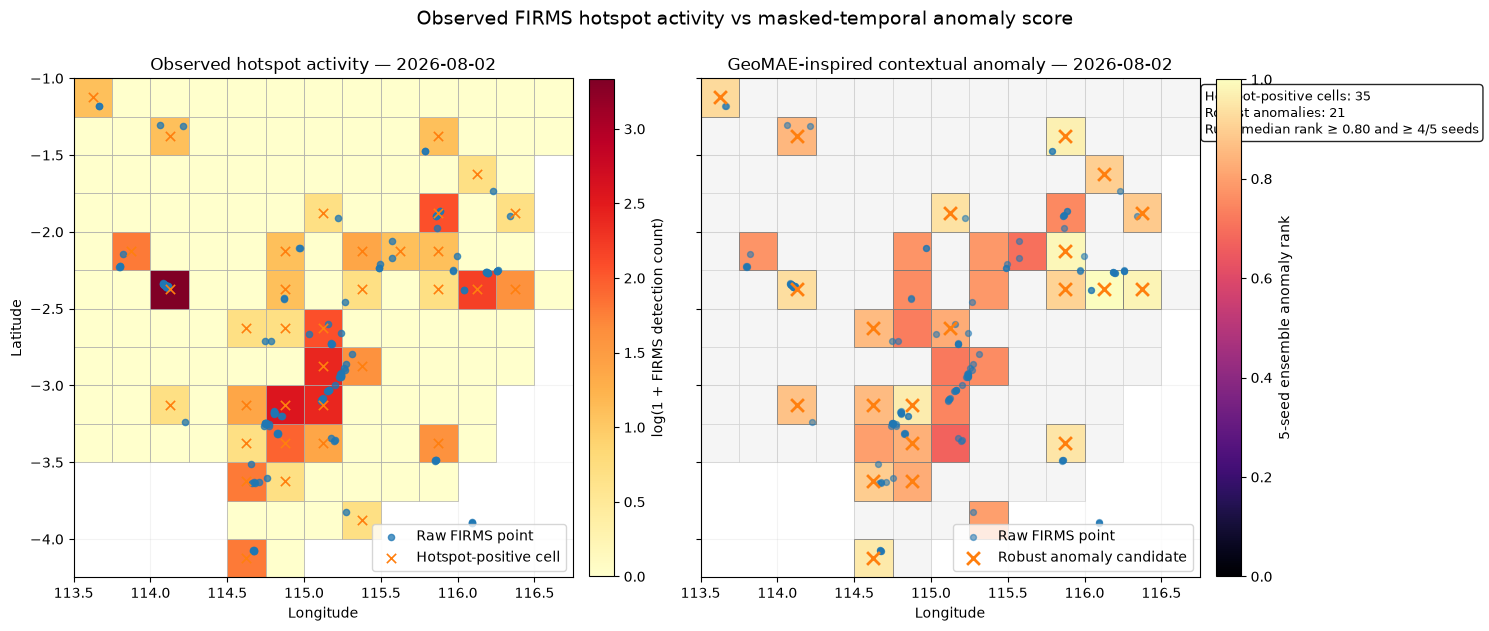

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\anomaly_map_visualization\t2\figures\geomae_anomaly_map_2026-08-02.png


In [8]:
CELL_STEP = 0.25
HALF = CELL_STEP / 2

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6.5),
    sharex=True,
    sharey=True,
)

ax_obs, ax_anom = axes

# LEFT: observed hotspot activity
obs_value = np.log1p(
    day["fire_count"].clip(lower=0)
)

obs_max = max(
    float(obs_value.max()),
    1e-6,
)

for row, value in zip(
    day.itertuples(index=False),
    obs_value,
):
    rect = Rectangle(
        (
            row.grid_lon - HALF,
            row.grid_lat - HALF,
        ),
        CELL_STEP,
        CELL_STEP,
        facecolor=plt.cm.YlOrRd(
            float(value) / obs_max
        ),
        edgecolor="0.65",
        linewidth=0.45,
    )
    ax_obs.add_patch(rect)

if len(firms):
    ax_obs.scatter(
        firms["firms_lon"],
        firms["firms_lat"],
        s=20,
        alpha=0.75,
        label="Raw FIRMS point",
        zorder=4,
    )

hot = day[
    day["fire_active"].eq(1)
]

ax_obs.scatter(
    hot["grid_lon"],
    hot["grid_lat"],
    marker="x",
    s=45,
    linewidths=1.2,
    label="Hotspot-positive cell",
    zorder=5,
)

ax_obs.set_title(
    f"Observed hotspot activity — {TARGET_DATE.date()}"
)

ax_obs.set_xlabel("Longitude")
ax_obs.set_ylabel("Latitude")
ax_obs.grid(alpha=0.15)
ax_obs.legend(loc="best")

sm_obs = plt.cm.ScalarMappable(
    cmap="YlOrRd",
    norm=plt.Normalize(
        vmin=0,
        vmax=obs_max,
    ),
)
sm_obs.set_array([])

cbar_obs = fig.colorbar(
    sm_obs,
    ax=ax_obs,
    fraction=0.046,
    pad=0.03,
)
cbar_obs.set_label(
    "log(1 + FIRMS detection count)"
)

# RIGHT: anomaly score on actual hotspot cells
for row in day.itertuples(index=False):
    rect = Rectangle(
        (
            row.grid_lon - HALF,
            row.grid_lat - HALF,
        ),
        CELL_STEP,
        CELL_STEP,
        facecolor="0.96",
        edgecolor="0.82",
        linewidth=0.45,
    )
    ax_anom.add_patch(rect)

for row in day_hot.itertuples(index=False):
    rank = float(
        row.ensemble_median_rank
    )

    rect = Rectangle(
        (
            row.grid_lon - HALF,
            row.grid_lat - HALF,
        ),
        CELL_STEP,
        CELL_STEP,
        facecolor=plt.cm.magma(rank),
        edgecolor="0.45",
        linewidth=0.55,
    )
    ax_anom.add_patch(rect)

if len(firms):
    ax_anom.scatter(
        firms["firms_lon"],
        firms["firms_lat"],
        s=18,
        alpha=0.55,
        label="Raw FIRMS point",
        zorder=4,
    )

if len(day_candidates):
    ax_anom.scatter(
        day_candidates["grid_lon"],
        day_candidates["grid_lat"],
        marker="x",
        s=85,
        linewidths=2.0,
        label="Robust anomaly candidate",
        zorder=6,
    )

ax_anom.set_title(
    f"GeoMAE-inspired contextual anomaly — {TARGET_DATE.date()}"
)

ax_anom.set_xlabel("Longitude")
ax_anom.grid(alpha=0.15)
ax_anom.legend(loc="best")

sm_anom = plt.cm.ScalarMappable(
    cmap="magma",
    norm=plt.Normalize(
        vmin=0,
        vmax=1,
    ),
)
sm_anom.set_array([])

cbar_anom = fig.colorbar(
    sm_anom,
    ax=ax_anom,
    fraction=0.046,
    pad=0.03,
)
cbar_anom.set_label(
    "5-seed ensemble anomaly rank"
)

xmin = day["grid_lon"].min() - HALF
xmax = day["grid_lon"].max() + HALF
ymin = day["grid_lat"].min() - HALF
ymax = day["grid_lat"].max() + HALF

for ax in axes:
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect(
        "equal",
        adjustable="box",
    )

info = (
    f"Hotspot-positive cells: {len(day_hot)}\n"
    f"Robust anomalies: {len(day_candidates)}\n"
    f"Rule: median rank ≥ 0.80 and ≥ 4/5 seeds"
)

ax_anom.text(
    1.01,
    0.98,
    info,
    transform=ax_anom.transAxes,
    ha="left",
    va="top",
    fontsize=9,
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.85,
    ),
)

fig.suptitle(
    "Observed FIRMS hotspot activity vs masked-temporal anomaly score",
    fontsize=14,
)

plt.tight_layout()

out_path = (
    FIG_DIR
    / f"geomae_anomaly_map_{TARGET_DATE.date()}.png"
)

plt.savefig(
    out_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", out_path)

## Optional presentation version

The next cell creates a single anomaly map and labels only the strongest few anomaly cells so it is easier to explain in a slide.

In [9]:
N_LABELS = 5

label_df = (
    day_candidates
    .sort_values(
        [
            "ensemble_median_rank",
            "high_seed_count",
            "ensemble_rank_iqr",
        ],
        ascending=[
            False,
            False,
            True,
        ],
    )
    .head(N_LABELS)
    .copy()
)

display(
    label_df[
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
            "fire_count",
            "frp_sum",
            "ensemble_median_rank",
            "high_seed_count",
        ]
        + (
            ["research_group"]
            if "research_group" in label_df.columns
            else []
        )
    ]
)

,cell_id,grid_lat,grid_lon,fire_count,frp_sum,ensemble_median_rank,high_seed_count,research_group
18,regional025_8_32,-2.375,116.125,8.0,84.98,1.000000,5,Emerging-3
20,regional025_9_31,-2.125,115.875,2.0,21.59,0.984962,5,Emerging-3
19,regional025_8_33,-2.375,116.375,4.0,23.30,0.977444,5,Persistent
4,regional025_12_31,-1.375,115.875,2.0,15.22,0.969925,5,Emerging-3
13,regional025_5_27,-3.125,114.875,12.0,46.26,0.962406,5,Persistent


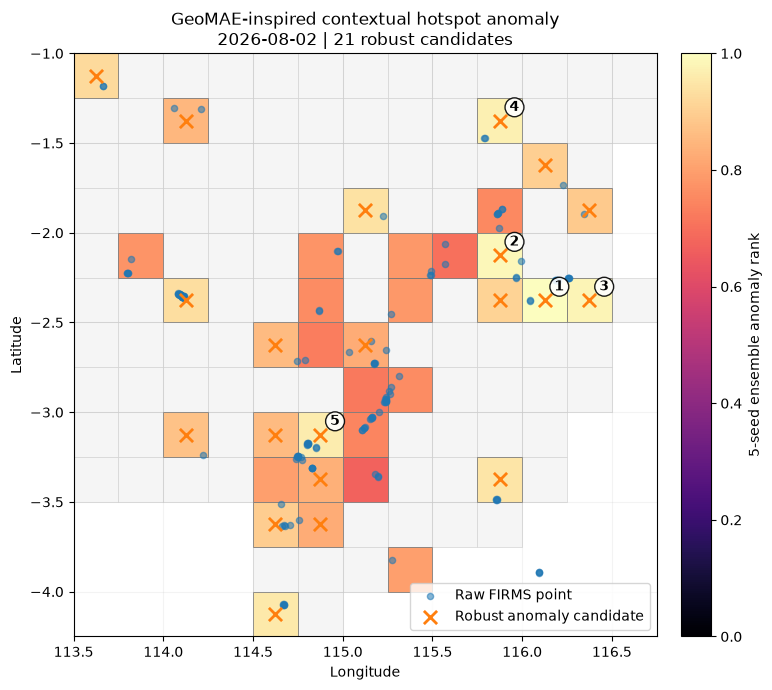

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\anomaly_map_visualization\t2\figures\geomae_anomaly_slide_2026-08-02.png


In [10]:
fig, ax = plt.subplots(
    figsize=(9, 7),
)

for row in day.itertuples(index=False):
    rect = Rectangle(
        (
            row.grid_lon - HALF,
            row.grid_lat - HALF,
        ),
        CELL_STEP,
        CELL_STEP,
        facecolor="0.96",
        edgecolor="0.82",
        linewidth=0.45,
    )
    ax.add_patch(rect)

for row in day_hot.itertuples(index=False):
    rank = float(
        row.ensemble_median_rank
    )

    rect = Rectangle(
        (
            row.grid_lon - HALF,
            row.grid_lat - HALF,
        ),
        CELL_STEP,
        CELL_STEP,
        facecolor=plt.cm.magma(rank),
        edgecolor="0.45",
        linewidth=0.55,
    )
    ax.add_patch(rect)

if len(firms):
    ax.scatter(
        firms["firms_lon"],
        firms["firms_lat"],
        s=20,
        alpha=0.55,
        label="Raw FIRMS point",
        zorder=4,
    )

if len(day_candidates):
    ax.scatter(
        day_candidates["grid_lon"],
        day_candidates["grid_lat"],
        marker="x",
        s=90,
        linewidths=2.0,
        label="Robust anomaly candidate",
        zorder=6,
    )

for i, row in enumerate(
    label_df.itertuples(index=False),
    start=1,
):
    ax.annotate(
        str(i),
        (
            row.grid_lon,
            row.grid_lat,
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            boxstyle="circle,pad=0.18",
            facecolor="white",
            alpha=0.9,
        ),
        zorder=8,
    )

sm = plt.cm.ScalarMappable(
    cmap="magma",
    norm=plt.Normalize(
        0,
        1,
    ),
)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.045,
    pad=0.03,
)
cbar.set_label(
    "5-seed ensemble anomaly rank"
)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect(
    "equal",
    adjustable="box",
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.set_title(
    (
        "GeoMAE-inspired contextual hotspot anomaly\n"
        f"{TARGET_DATE.date()} | "
        f"{len(day_candidates)} robust candidates"
    )
)

ax.grid(alpha=0.15)
ax.legend(loc="best")

plt.tight_layout()

slide_path = (
    FIG_DIR
    / f"geomae_anomaly_slide_{TARGET_DATE.date()}.png"
)

plt.savefig(
    slide_path,
    dpi=220,
    bbox_inches="tight",
)

plt.show()

print("Saved:", slide_path)

## How to explain this figure

> “Minggu lalu warna grid menunjukkan next-day risk: lokasi mana yang diperkirakan akan menjadi hotspot. Pada visualisasi minggu ini saya memakai grid yang sama, tetapi warna sekarang menunjukkan anomaly rank. Jadi saya hanya melihat hotspot yang benar-benar muncul, lalu mengukur seberapa sulit hotspot tersebut direkonstruksi dari temporal fire context sebelumnya. Semakin tinggi anomaly rank, semakin tidak sesuai event tersebut dengan pola yang dipelajari model. Tanda × adalah kandidat yang stabil di minimal 4 dari 5 random seed.”

### Key distinction

**Prediction map**
- question: *where will a hotspot appear tomorrow?*

**Anomaly map**
- question: *among observed hotspots, which events are unusually difficult to explain from preceding context?*

## Recommended next extension

If the supervisor wants the same date as the September next-day risk figure (**2026-09-02**), first score that date with the frozen five-seed `T_FIRE` anomaly ensemble.

Then create a three-panel figure:

`Next-day risk (Sep 1 → Sep 2) → Actual FIRMS Sep 2 → Anomaly rank Sep 2`

That is the cleanest visual bridge between last week's and this week's progress.